we have to functions in validation used by fastoma on checks the number of proteins the other checks whether it is likely that the protein is not an aminoacid sequence, but for short protein sequences because of an overlap this creates an error

In [1]:

     43 def check_proteome(species_names, prot_recs_lists, proteome_folder):
     44     # ids_set=set()
     45     isOk = True
     46     num_prots_all = 0
     47     for species_name in species_names:
     48         prot_recs_list = prot_recs_lists[species_name]
     49         prot_recs_ids = [prot_rec.id for prot_rec in prot_recs_list]
     50         if len(prot_recs_ids)!= len(set(prot_recs_ids)):
     51             logger.error("It seems that at least of the protein id in fasta file %s is repeated. Note that only part of a fasta record before space is considered.",species_name)
     52             logger.error("Check input failed. FastOMA halted!")
     53             return False
     54         for prot_rec_id in prot_recs_ids:
     55             if len(prot_rec_id) > 60:   # todo 85 is the limit without considering ||s.
     56                 logger.error("The protein ID %s is too long in species %s.fa, which should be changed. Please make sure it will be still unique.", prot_rec_id, species_name)  # (root cause issue due to truncation by fastTree)
     57                 logger.error("Check input failed. FastOMA halted!")
     58                 return False
     59                 
     60         # checking only first record in each species  # for ii in range(len(prot_recs_list)):
     61         # check that at least 20% of all residue are not DNA/RNA characters (as a check for protein sequences)
     62         residue_cnts = collections.Counter(itertools.chain.from_iterable(rec.seq.upper() for rec in prot_recs_list))
     63         aa_chars = set(extended_protein_letters) - set(unambiguous_dna_letters) - set(unambiguous_rna_letters) - set('N')
     64         total_aa = sum([residue_cnts[aa] for aa in aa_chars])
     65         if total_aa / sum(residue_cnts.values()) < 0.2:
     66             logger.error("Looks like genomics sequences used in '%s'. Proteome contains only %.1f%% amino acids letters.", species_name,  100 * total_aa / sum(residue_cnts.values()))
     67             return False
     68 
     69         num_prots = len(prot_recs_list)  # >EP00159_Fonticula_alba_P004948_XP_009497064.1_small_nuclear_ribonucleoprotein_B_and_B'_Fonticula_alba||691883||1155004948
     70         num_prots_all += num_prots
     71         # todo , check duplicated Ids should it be done on all species ?
     72 
     73         if num_prots <= 2:
     74             logger.error("The input proteome looks empty or too few proteins or Bio.SeqIO couldn't read it, %s/%s.fa", proteome_folder, species_name)
     75             isOk = False
     76 
     77     # todo write new protoems with cleaned record ids, keep the mapping, to be used in orthoxml writing
     78     # use the mapping back for orthoxml
     79     logger.info("There are %d proteins in total in the input proteome folder.", num_prots_all)
     80     return isOk


SyntaxError: invalid syntax (3336431798.py, line 1)

In [5]:
from pathlib import Path
from collections import Counter
from datetime import datetime

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from Bio import SeqIO
from Bio.Data.IUPACData import (
    extended_protein_letters,
    unambiguous_dna_letters,
    unambiguous_rna_letters,
)

run_dir = Path(
    "/home/saschabrown/evomics_projects/saschabrown/creating fasta files"
)

proteome_dir = run_dir / "fastoma_input" / "proteome"

analysis_dir = (
    run_dir
    / "cafa_input_validation"
    / datetime.now().strftime("%Y%m%d_%H%M%S")
)

if not proteome_dir.is_dir():
    raise FileNotFoundError(proteome_dir)

# Numeric filenames identify CAFA inputs in our dataset.
fasta_files = sorted(
    filename
    for filename in proteome_dir.glob("*.fa")
    if filename.is_file() and filename.stem.isdigit()
)

if not fasta_files:
    raise ValueError("No CAFA FASTA files found.")

# Reproduce the character set in the installed FastOMA check.
protein_specific_letters = (
    set(extended_protein_letters)
    - set(unambiguous_dna_letters)
    - set(unambiguous_rna_letters)
    - {"N"}
)

print("CAFA files to inspect:", len(fasta_files))
print("Input folder:", proteome_dir)
print("Results folder:", analysis_dir)

CAFA files to inspect: 8452
Input folder: /home/saschabrown/evomics_projects/saschabrown/creating fasta files/fastoma_input/proteome
Results folder: /home/saschabrown/evomics_projects/saschabrown/creating fasta files/cafa_input_validation/20261009_145901


In [6]:
rows = []

for number, filename in enumerate(fasta_files, start=1):
    protein_count = 0
    empty_sequences = 0
    residues = Counter()
    parse_error = ""

    try:
        for record in SeqIO.parse(filename, "fasta"):
            protein_count += 1
            sequence = str(record.seq).upper()

            if not sequence:
                empty_sequences += 1

            residues.update(sequence)

    except Exception as error:
        parse_error = f"{type(error).__name__}: {error}"

    parsed_ok = not parse_error
    total_residues = sum(residues.values())

    protein_specific_count = sum(
        residues[letter] for letter in protein_specific_letters
    )

    fraction = (
        protein_specific_count / total_residues
        if parsed_ok and total_residues > 0
        else float("nan")
    )

    low_count = parsed_ok and protein_count <= 2
    composition_flag = (
        parsed_ok
        and total_residues > 0
        and fraction < 0.20
    )
    no_residues = parsed_ok and total_residues == 0

    rows.append({
        "ncbi_taxid": filename.stem,
        "filename": filename.name,
        "fasta_location": str(filename),
        "protein_count": protein_count if parsed_ok else pd.NA,
        "empty_sequence_count": empty_sequences if parsed_ok else pd.NA,
        "total_residues": total_residues if parsed_ok else pd.NA,
        "protein_specific_fraction": fraction,
        "flag_le_2_proteins": low_count,
        "flag_composition": composition_flag,
        "flag_no_residues": no_residues,
        "parse_error": parse_error,
        "flag_any": (
            low_count or composition_flag or no_residues or not parsed_ok
        ),
    })

    if number % 500 == 0 or number == len(fasta_files):
        print(f"Inspected {number}/{len(fasta_files)} CAFA files")

results = pd.DataFrame(rows)

for column in [
    "protein_count",
    "empty_sequence_count",
    "total_residues",
]:
    results[column] = results[column].astype("Int64")

print("Inspection finished.")

Inspected 500/8452 CAFA files
Inspected 1000/8452 CAFA files
Inspected 1500/8452 CAFA files
Inspected 2000/8452 CAFA files
Inspected 2500/8452 CAFA files
Inspected 3000/8452 CAFA files
Inspected 3500/8452 CAFA files
Inspected 4000/8452 CAFA files
Inspected 4500/8452 CAFA files
Inspected 5000/8452 CAFA files
Inspected 5500/8452 CAFA files
Inspected 6000/8452 CAFA files
Inspected 6500/8452 CAFA files
Inspected 7000/8452 CAFA files
Inspected 7500/8452 CAFA files
Inspected 8000/8452 CAFA files
Inspected 8452/8452 CAFA files
Inspection finished.


In [7]:
low_count_files = results.loc[
    results["flag_le_2_proteins"]
].copy()

composition_flags = results.loc[
    results["flag_composition"]
].copy()

both_flags = (
    results["flag_le_2_proteins"]
    & results["flag_composition"]
)

summary = pd.DataFrame([
    {
        "category": "All CAFA files inspected",
        "files": len(results),
    },
    {
        "category": "Files containing 0 proteins",
        "files": int(results["protein_count"].eq(0).sum()),
    },
    {
        "category": "Files containing 1 protein",
        "files": int(results["protein_count"].eq(1).sum()),
    },
    {
        "category": "Files containing 2 proteins",
        "files": int(results["protein_count"].eq(2).sum()),
    },
    {
        "category": "Files containing ≤2 proteins",
        "files": len(low_count_files),
    },
    {
        "category": "Composition flags",
        "files": len(composition_flags),
    },
    {
        "category": "Files failing both checks",
        "files": int(both_flags.sum()),
    },
    {
        "category": "Files without sequence residues",
        "files": int(results["flag_no_residues"].sum()),
    },
    {
        "category": "Files with parsing errors",
        "files": int(results["parse_error"].ne("").sum()),
    },
    {
        "category": "Files with any recorded flag",
        "files": int(results["flag_any"].sum()),
    },
])

summary["percent_of_files"] = (
    100 * summary["files"] / len(results)
).round(2)

display(summary)

print("\nFirst 20 CAFA files containing ≤2 proteins:")
display(
    low_count_files[
        ["ncbi_taxid", "filename", "protein_count", "flag_composition"]
    ].head(20)
)

print("\nComposition flags requiring review:")
display(
    composition_flags[
        [
            "ncbi_taxid",
            "filename",
            "protein_count",
            "protein_specific_fraction",
            "flag_le_2_proteins",
        ]
    ].sort_values("protein_specific_fraction")
)

,category,files,percent_of_files
0,All CAFA files inspected,8452,100.00
1,Files containing 0 proteins,0,0.00
2,Files containing 1 protein,4008,47.42
3,Files containing 2 proteins,1213,14.35
4,Files containing ≤2 proteins,5221,61.77
5,Composition flags,1,0.01
6,Files failing both checks,1,0.01
7,Files without sequence residues,0,0.00
8,Files with parsing errors,0,0.00
9,Files with any recorded flag,5221,61.77



First 20 CAFA files containing ≤2 proteins:


,ncbi_taxid,filename,protein_count,flag_composition
0,10007,10007.fa,1,False
1,10009,10009.fa,2,False
2,10012,10012.fa,1,False
4,10013,10013.fa,1,False
5,100151,100151.fa,1,False
6,10017,10017.fa,1,False
7,10018,10018.fa,1,False
8,10019,10019.fa,1,False
9,10020,10020.fa,2,False
10,100209,100209.fa,1,False



Composition flags requiring review:


,ncbi_taxid,filename,protein_count,protein_specific_fraction,flag_le_2_proteins
7272,8047,8047.fa,2,0.171429,True


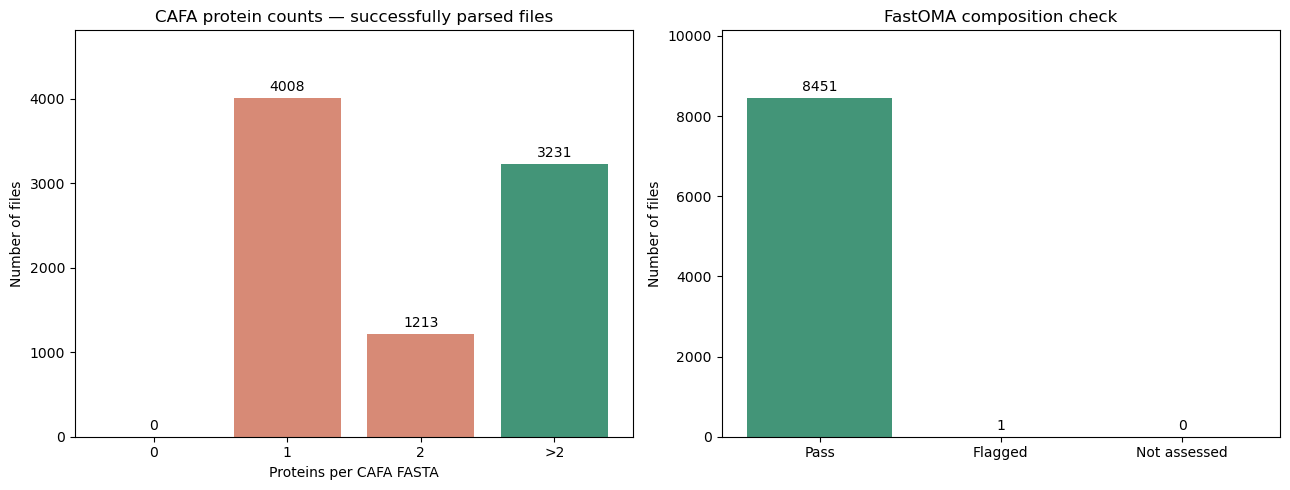

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Protein-count categories are mutually exclusive.
protein_counts = [
    int(results["protein_count"].eq(0).sum()),
    int(results["protein_count"].eq(1).sum()),
    int(results["protein_count"].eq(2).sum()),
    int(results["protein_count"].gt(2).sum()),
]

bars = axes[0].bar(
    ["0", "1", "2", ">2"],
    protein_counts,
    color=["#D78A76", "#D78A76", "#D78A76", "#439578"],
)
axes[0].bar_label(bars, padding=3)
axes[0].set_xlabel("Proteins per CAFA FASTA")
axes[0].set_ylabel("Number of files")
axes[0].set_title("CAFA protein counts — successfully parsed files")
axes[0].set_ylim(0, max(1, max(protein_counts)) * 1.2)

# Composition can only be calculated for parsed, non-empty sequences.
assessed = results["protein_specific_fraction"].notna()

composition_counts = [
    int((assessed & ~results["flag_composition"]).sum()),
    int(results["flag_composition"].sum()),
    int((~assessed).sum()),
]

bars = axes[1].bar(
    ["Pass", "Flagged", "Not assessed"],
    composition_counts,
    color=["#439578", "#D78A76", "#999999"],
)
axes[1].bar_label(bars, padding=3)
axes[1].set_ylabel("Number of files")
axes[1].set_title("FastOMA composition check")
axes[1].set_ylim(0, max(1, max(composition_counts)) * 1.2)

plt.tight_layout()
plt.show()

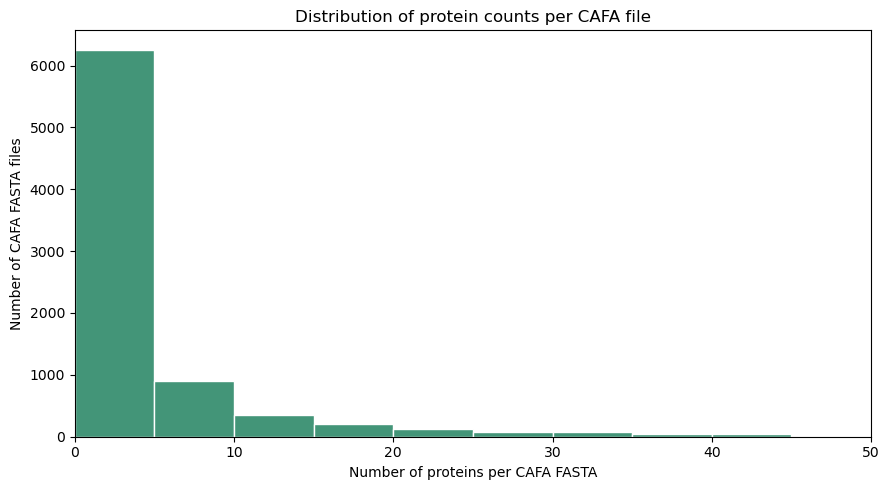

Total proteins in the inspected CAFA FASTAs: 224,307


In [20]:
import matplotlib.pyplot as plt

counts = results["protein_count"].dropna().astype(int)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    counts,
    bins=range(0, 50, 5),
    color="#439578",
    edgecolor="white",
)

ax.set_xlim(0, 50)
ax.set_xlabel("Number of proteins per CAFA FASTA")
ax.set_ylabel("Number of CAFA FASTA files")
ax.set_title("Distribution of protein counts per CAFA file")

plt.tight_layout()
plt.show()
total_proteins = results["protein_count"].sum()

print(f"Total proteins in the inspected CAFA FASTAs: {total_proteins:,}")

Total CAFA proteins: 224,307


,minimum_length,proteins_removed,fraction_removed,percent_removed,proteins_retained
0,10,788,0.003513,0.351304,223519
1,11,1145,0.005105,0.510461,223162
2,12,1599,0.007129,0.712862,222708
3,13,1802,0.008034,0.803363,222505
4,14,2032,0.009059,0.905901,222275
5,15,2233,0.009955,0.995511,222074
6,16,2534,0.011297,1.129702,221773
7,17,2681,0.011952,1.195237,221626
8,18,2911,0.012978,1.297775,221396
9,19,3041,0.013557,1.355731,221266


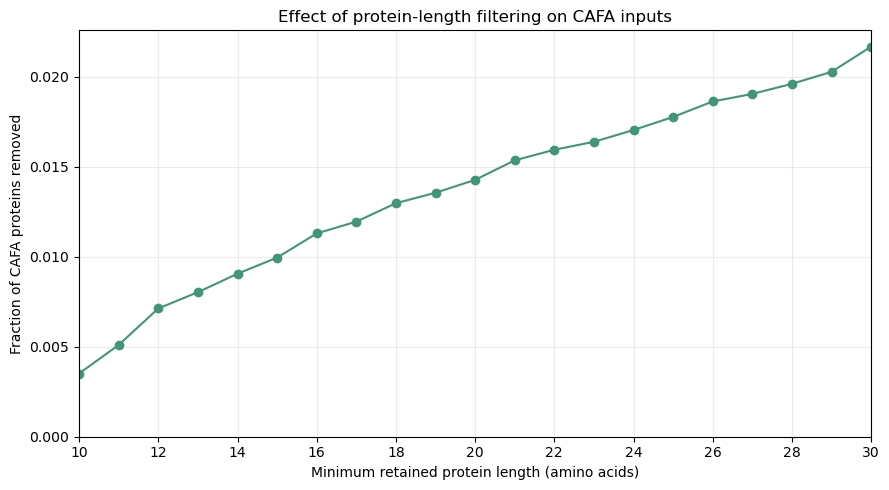

In [23]:
from collections import Counter
from Bio import SeqIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the CAFA-only fasta_files list defined earlier.
length_counts = Counter()

for filename in fasta_files:
    for record in SeqIO.parse(filename, "fasta"):
        length_counts[len(record.seq)] += 1

total_proteins = sum(length_counts.values())

if total_proteins == 0:
    raise ValueError("No proteins found in the selected FASTAs.")

# Calculate the number removed at each minimum-length threshold.
cutoff_analysis = pd.DataFrame({
    "minimum_length": range(10, 31)
})

cutoff_analysis["proteins_removed"] = [
    sum(count for length, count in length_counts.items() if length < cutoff)
    for cutoff in cutoff_analysis["minimum_length"]
]

cutoff_analysis["fraction_removed"] = (
    cutoff_analysis["proteins_removed"] / total_proteins
)

cutoff_analysis["percent_removed"] = (
    100 * cutoff_analysis["fraction_removed"]
)

cutoff_analysis["proteins_retained"] = (
    total_proteins - cutoff_analysis["proteins_removed"]
)

print(f"Total CAFA proteins: {total_proteins:,}")
display(cutoff_analysis)

# One denominator across all thresholds: all inspected CAFA proteins.
fig_length, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    cutoff_analysis["minimum_length"],
    cutoff_analysis["fraction_removed"],
    marker="o",
    color="#439578",
)

ax.set_xticks(np.arange(10, 31, 2))
ax.set_xlim(10, 30)
ax.set_ylim(bottom=0)
ax.set_xlabel("Minimum retained protein length (amino acids)")
ax.set_ylabel("Fraction of CAFA proteins removed")
ax.set_title("Effect of protein-length filtering on CAFA inputs")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Save the table and plot in this notebook's analysis folder.
analysis_dir.mkdir(parents=True, exist_ok=True)

cutoff_analysis.to_csv(
    analysis_dir / "cafa_length_cutoff_analysis.tsv",
    sep="\t",
    index=False,
)

fig_length.savefig(
    analysis_dir / "cafa_length_cutoff_analysis.png",
    dpi=200,
    bbox_inches="tight",
)

,minimum_length,total_files,empty_files,newly_empty_files,fraction_empty
0,10,8452,31,31,0.003668
1,11,8452,51,51,0.006034
2,12,8452,80,80,0.009465
3,13,8452,92,92,0.010885
4,14,8452,114,114,0.013488
5,15,8452,141,141,0.016682
6,16,8452,166,166,0.019640
7,17,8452,173,173,0.020469
8,18,8452,242,242,0.028632
9,19,8452,257,257,0.030407


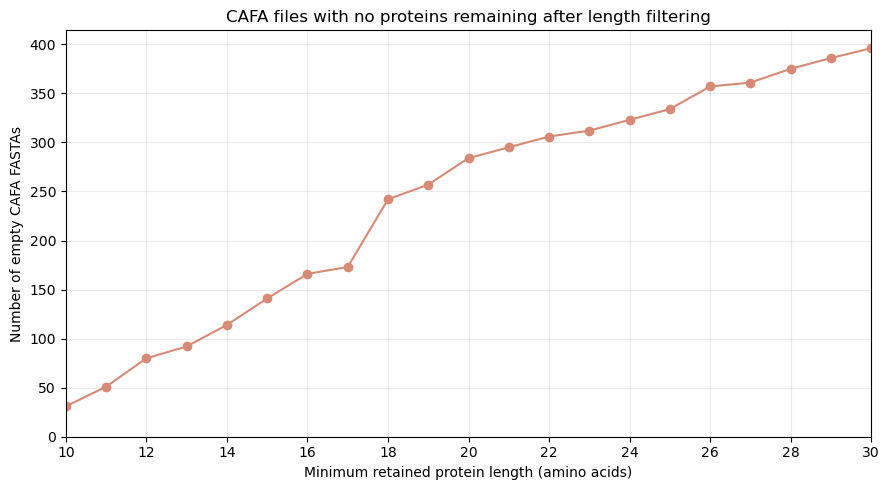

Files empty at a minimum length of 20:


,minimum_length,ncbi_taxid,filename,fasta_location,original_protein_count,newly_empty
1347,20,100756,100756.fa,/home/saschabrown/evomics_projects/saschabrown...,1,True
1348,20,101187,101187.fa,/home/saschabrown/evomics_projects/saschabrown...,1,True
1349,20,101285,101285.fa,/home/saschabrown/evomics_projects/saschabrown...,2,True
1350,20,101289,101289.fa,/home/saschabrown/evomics_projects/saschabrown...,2,True
1351,20,103373,103373.fa,/home/saschabrown/evomics_projects/saschabrown...,4,True
...,...,...,...,...,...,...
1626,20,91419,91419.fa,/home/saschabrown/evomics_projects/saschabrown...,2,True
1627,20,91420,91420.fa,/home/saschabrown/evomics_projects/saschabrown...,3,True
1628,20,95134,95134.fa,/home/saschabrown/evomics_projects/saschabrown...,1,True
1629,20,97181,97181.fa,/home/saschabrown/evomics_projects/saschabrown...,3,True


In [25]:
from Bio import SeqIO
import pandas as pd
import matplotlib.pyplot as plt

# Record protein lengths separately for each CAFA file.
lengths_by_file = {
    filename: [len(record.seq) for record in SeqIO.parse(filename, "fasta")]
    for filename in fasta_files
}

summary_rows = []
empty_rows = []

for cutoff in range(10, 31):
    empty_count = 0
    newly_empty_count = 0

    for filename, lengths in lengths_by_file.items():
        retained = sum(length >= cutoff for length in lengths)

        if retained == 0:
            empty_count += 1
            newly_empty_count += int(len(lengths) > 0)

            empty_rows.append({
                "minimum_length": cutoff,
                "ncbi_taxid": filename.stem,
                "filename": filename.name,
                "fasta_location": str(filename),
                "original_protein_count": len(lengths),
                "newly_empty": len(lengths) > 0,
            })

    summary_rows.append({
        "minimum_length": cutoff,
        "total_files": len(lengths_by_file),
        "empty_files": empty_count,
        "newly_empty_files": newly_empty_count,
        "fraction_empty": empty_count / len(lengths_by_file),
    })

empty_summary = pd.DataFrame(summary_rows)

empty_files = pd.DataFrame(
    empty_rows,
    columns=[
        "minimum_length",
        "ncbi_taxid",
        "filename",
        "fasta_location",
        "original_protein_count",
        "newly_empty",
    ],
)

display(empty_summary)

# Plot the number of empty files at each cutoff.
fig_empty, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    empty_summary["minimum_length"],
    empty_summary["empty_files"],
    marker="o",
    color="#D78A76",
)

ax.set_xticks(range(10, 31, 2))
ax.set_xlim(10, 30)
ax.set_ylim(bottom=0)
ax.set_xlabel("Minimum retained protein length (amino acids)")
ax.set_ylabel("Number of empty CAFA FASTAs")
ax.set_title("CAFA files with no proteins remaining after length filtering")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# List files that would be empty at a cutoff of 20.
print("Files empty at a minimum length of 20:")
display(empty_files.loc[empty_files["minimum_length"] == 20])

# Save reports.
analysis_dir.mkdir(parents=True, exist_ok=True)

empty_summary.to_csv(
    analysis_dir / "cafa_empty_files_by_length_cutoff.tsv",
    sep="\t",
    index=False,
)

empty_files.to_csv(
    analysis_dir / "cafa_empty_file_details.tsv",
    sep="\t",
    index=False,
)

fig_empty.savefig(
    analysis_dir / "cafa_empty_files_by_length_cutoff.png",
    dpi=200,
    bbox_inches="tight",
)

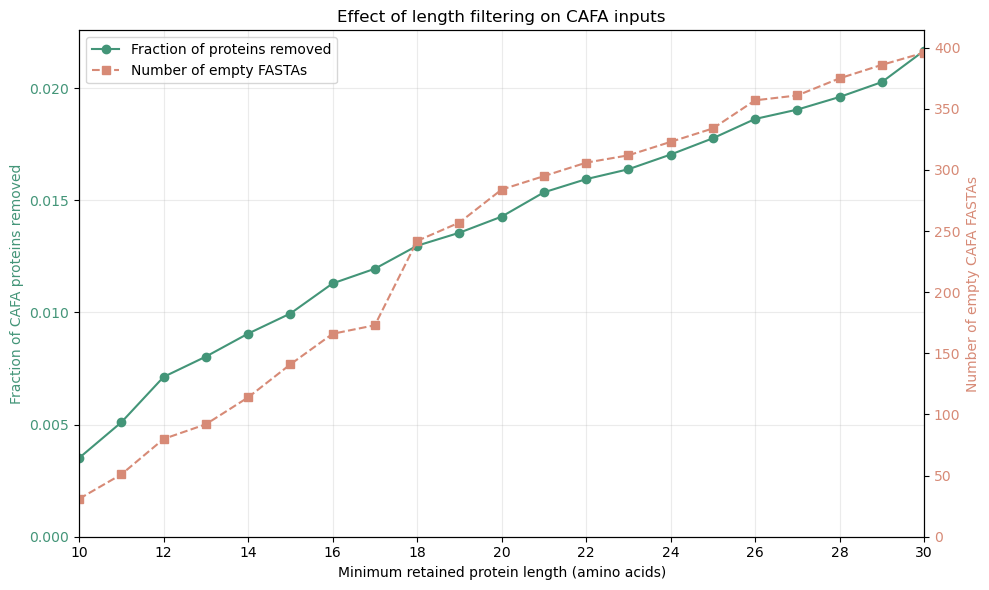

In [27]:
import matplotlib.pyplot as plt

fig_combined, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()

protein_line, = ax1.plot(
    cutoff_analysis["minimum_length"],
    cutoff_analysis["fraction_removed"],
    color="#439578",
    marker="o",
    label="Fraction of proteins removed",
)

empty_line, = ax2.plot(
    empty_summary["minimum_length"],
    empty_summary["empty_files"],
    color="#D78A76",
    marker="s",
    linestyle="--",
    label="Number of empty FASTAs",
)

ax1.set_xlabel("Minimum retained protein length (amino acids)")
ax1.set_ylabel("Fraction of CAFA proteins removed", color="#439578")
ax2.set_ylabel("Number of empty CAFA FASTAs", color="#D78A76")

ax1.tick_params(axis="y", labelcolor="#439578")
ax2.tick_params(axis="y", labelcolor="#D78A76")

ax1.set_xticks(range(10, 31, 2))
ax1.set_xlim(10, 30)
ax1.set_ylim(bottom=0)
ax2.set_ylim(bottom=0)

ax1.legend(
    handles=[protein_line, empty_line],
    loc="upper left",
)

ax1.set_title("Effect of length filtering on CAFA inputs")
ax1.grid(alpha=0.25)

plt.tight_layout()
plt.show()

analysis_dir.mkdir(parents=True, exist_ok=True)
fig_combined.savefig(
    analysis_dir / "cafa_length_filtering_combined.png",
    dpi=200,
    bbox_inches="tight",
)

In [28]:
### Record CAFA proteins that would be filtered at a minimum length of 15 aa

from pathlib import Path
from Bio import SeqIO
from ete4 import NCBITaxa
import pandas as pd
from IPython.display import display

minimum_length = 15

run_dir = Path(
    "/home/saschabrown/evomics_projects/saschabrown/creating fasta files"
)

proteome_dir = run_dir / "fastoma_input" / "proteome"
report_dir = run_dir / "filtered data"

# Numeric filenames identify CAFA inputs in our combined dataset.
cafa_files = sorted(
    filename
    for filename in proteome_dir.glob("*.fa")
    if filename.is_file() and filename.stem.isdigit()
)

if not cafa_files:
    raise ValueError(f"No CAFA FASTA files found in {proteome_dir}")

# Read scientific names from the local NCBI taxonomy database.
ncbi = NCBITaxa()
taxid_names = ncbi.get_taxid_translator(
    [int(filename.stem) for filename in cafa_files]
)

protein_rows = []
species_rows = []

for filename in cafa_files:
    taxid = filename.stem
    scientific_name = taxid_names.get(int(taxid), "Unresolved")

    total = 0
    removed = 0

    for record in SeqIO.parse(filename, "fasta"):
        total += 1

        # Keep proteins of exactly 15 aa or longer.
        if len(record.seq) >= minimum_length:
            continue

        # Expected header: ACCESSION_TAXID_train/test
        parts = record.id.rsplit("_", 2)

        if (
            len(parts) != 3
            or parts[1] != taxid
            or parts[2] not in {"train", "test"}
        ):
            raise ValueError(f"Unexpected CAFA header: {record.id}")

        accession, _, dataset = parts
        removed += 1

        protein_rows.append({
            "protein_id": record.id,
            "uniprot_accession": accession,
            "dataset": dataset,
            "ncbi_taxid": taxid,
            "scientific_name": scientific_name,
            "protein_length": len(record.seq),
            "minimum_length": minimum_length,
            "filter_reason": "protein_length_less_than_15aa",
            "filename": filename.name,
            "fasta_location": str(filename),
        })

    species_rows.append({
        "ncbi_taxid": taxid,
        "scientific_name": scientific_name,
        "filename": filename.name,
        "fasta_location": str(filename),
        "minimum_length": minimum_length,
        "original_proteins": total,
        "proteins_below_cutoff": removed,
        "proteins_retained": total - removed,
        "newly_empty_after_filter": total > 0 and total == removed,
    })

species_report = pd.DataFrame(species_rows)

filtered_proteins = pd.DataFrame(
    protein_rows,
    columns=[
        "protein_id",
        "uniprot_accession",
        "dataset",
        "ncbi_taxid",
        "scientific_name",
        "protein_length",
        "minimum_length",
        "filter_reason",
        "filename",
        "fasta_location",
    ],
)

# Include whether the corresponding species would become empty.
filtered_proteins = filtered_proteins.merge(
    species_report[
        ["ncbi_taxid", "proteins_retained", "newly_empty_after_filter"]
    ],
    on="ncbi_taxid",
    how="left",
    validate="many_to_one",
)

assert len(filtered_proteins) == species_report["proteins_below_cutoff"].sum()

# Save reports, leaving all input FASTAs unchanged.
report_dir.mkdir(parents=True, exist_ok=True)

protein_report_file = (
    report_dir / "cafa_proteins_to_filter_length_less_than_15aa.tsv"
)

species_report_file = (
    report_dir / "cafa_species_filtering_summary_minimum_length_15aa.tsv"
)

filtered_proteins.to_csv(
    protein_report_file, sep="\t", index=False
)

species_report.to_csv(
    species_report_file, sep="\t", index=False
)

print("CAFA files inspected:", len(cafa_files))
print("Total CAFA proteins:", species_report["original_proteins"].sum())
print("Proteins shorter than 15 aa:", len(filtered_proteins))
print("Proteins retained:", species_report["proteins_retained"].sum())
print("Affected species:", filtered_proteins["ncbi_taxid"].nunique())
print(
    "Species becoming empty:",
    species_report["newly_empty_after_filter"].sum(),
)

display(filtered_proteins.head(20))

print("\nProtein report:", protein_report_file)
print("Species summary:", species_report_file)

CAFA files inspected: 8452
Total CAFA proteins: 224307
Proteins shorter than 15 aa: 2233
Proteins retained: 222074
Affected species: 620
Species becoming empty: 141


,protein_id,uniprot_accession,dataset,ncbi_taxid,scientific_name,protein_length,minimum_length,filter_reason,filename,fasta_location,proteins_retained,newly_empty_after_filter
0,B3A0L4_100756_train,B3A0L4,train,100756,Hericium coralloides,10,15,protein_length_less_than_15aa,100756.fa,/home/saschabrown/evomics_projects/saschabrown...,0,True
1,P83853_10090_test,P83853,test,10090,Mus musculus,8,15,protein_length_less_than_15aa,10090.fa,/home/saschabrown/evomics_projects/saschabrown...,17230,False
2,P38640_10090_test,P38640,test,10090,Mus musculus,9,15,protein_length_less_than_15aa,10090.fa,/home/saschabrown/evomics_projects/saschabrown...,17230,False
3,P38641_10090_test,P38641,test,10090,Mus musculus,7,15,protein_length_less_than_15aa,10090.fa,/home/saschabrown/evomics_projects/saschabrown...,17230,False
4,P38644_10090_test,P38644,test,10090,Mus musculus,8,15,protein_length_less_than_15aa,10090.fa,/home/saschabrown/evomics_projects/saschabrown...,17230,False
5,P99032_10090_test,P99032,test,10090,Mus musculus,12,15,protein_length_less_than_15aa,10090.fa,/home/saschabrown/evomics_projects/saschabrown...,17230,False
6,P38639_10090_test,P38639,test,10090,Mus musculus,5,15,protein_length_less_than_15aa,10090.fa,/home/saschabrown/evomics_projects/saschabrown...,17230,False
7,P83854_10090_test,P83854,test,10090,Mus musculus,10,15,protein_length_less_than_15aa,10090.fa,/home/saschabrown/evomics_projects/saschabrown...,17230,False
8,P38642_10090_test,P38642,test,10090,Mus musculus,7,15,protein_length_less_than_15aa,10090.fa,/home/saschabrown/evomics_projects/saschabrown...,17230,False
9,P38643_10090_test,P38643,test,10090,Mus musculus,11,15,protein_length_less_than_15aa,10090.fa,/home/saschabrown/evomics_projects/saschabrown...,17230,False



Protein report: /home/saschabrown/evomics_projects/saschabrown/creating fasta files/filtered data/cafa_proteins_to_filter_length_less_than_15aa.tsv
Species summary: /home/saschabrown/evomics_projects/saschabrown/creating fasta files/filtered data/cafa_species_filtering_summary_minimum_length_15aa.tsv
